In [139]:
import pandas as pd
import numpy as np
import random
import os

import matplotlib.pyplot as plt

In [140]:
# kolory
orig_fun_color = "#2ca02c"
true_color     = "#333333"
pred_color     = "#1f77b4"

train_color = "#1f77b4"
val_color   = "#d62728"

line_width = 1

In [141]:
def f(a,b,c,d,x):
    # return a*x**2 + b*x + c
    return np.sin(a*np.pi*x) + b*np.sin(c*np.pi*x) + d

def f_dev(a,b,c,d,x):
    # return 2*a*x + b
    return a*np.pi*np.cos(a*np.pi*x) + b*c*np.pi*np.cos(c*np.pi*x) + d

def generate_row(x_min, x_max, num_of_steps, a, b, c, d):
    # x_grid = generate_grid(x_min, x_max, num_of_steps)
    x_grid = np.linspace(x_min, x_max, num_of_steps)
    y_grid = f(a, b, c, d, x_grid)
    y_dev_grid = f_dev(a, b, c, d, x_grid)
    return x_grid, y_grid, y_dev_grid

def generate_dataset(x_min, x_max, num_of_steps, num_rows):
    dataset = pd.DataFrame(columns = 
                            [f"y_{i}" for i in range(num_of_steps)] +
                            [f"y_dev_{i}" for i in range(num_of_steps)]
                            )
    for _ in range(num_rows):
        a, b, c, d = random.uniform(-10, 10), random.uniform(-10, 10), random.uniform(-10, 10), random.uniform(-10, 10)
        x_grid, y_grid, y_dev_grid = generate_row(x_min, x_max, num_of_steps, a, b, c, d)
        # print(len(x_grid), len(y_grid), len(y_dev_grid))
        # print(len(dataset.columns))
        # print(num_of_steps)
        row = pd.DataFrame(np.concatenate([y_grid, y_dev_grid]).reshape(1, -1), columns=dataset.columns)
        dataset = pd.concat([dataset, row], axis=0, ignore_index=True)
    return dataset

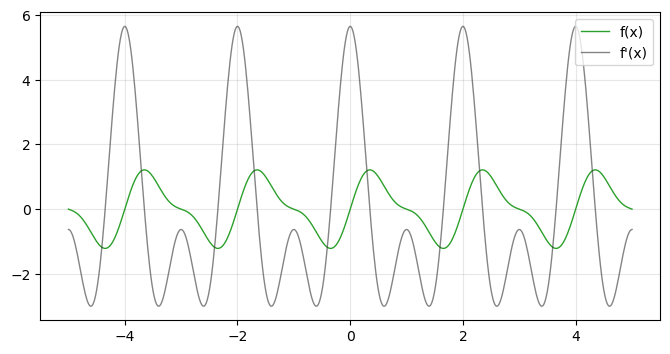

In [164]:
num_of_steps = 500
# a, b, c, d = random.uniform(-10, 10), random.uniform(-10, 10), random.uniform(-10, 10), random.uniform(-10, 10)
a, b, c, d = 1, 0.4, 2, 0
x_grid, y_grid, y_dev_grid = generate_row(-5, 5, num_of_steps, a, b, c, d)
x_grid, y_grid, y_dev_grid

x_axis = np.linspace(-5, 5, num_of_steps)
plt.figure(figsize=(8, 4))
plt.plot(x_axis, y_grid, linewidth=line_width, color=orig_fun_color)
plt.plot(x_axis, y_dev_grid, linewidth=line_width, color=true_color, alpha=0.6)
plt.grid(alpha=0.3)
plt.legend(["f(x)", "f'(x)"], loc="upper right")
plt.show()

### Training MLP

In [143]:
from sklearn.model_selection import train_test_split

num_of_steps = 100
df = generate_dataset(-20, 20, num_of_steps, 100)
train_data, test_data = train_test_split(df, test_size=0.2, random_state=42)
train_data.head()

C:\Users\laura\AppData\Local\Temp\ipykernel_39400\1236327448.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  dataset = pd.concat([dataset, row], axis=0, ignore_index=True)


,y_0,y_1,y_2,y_3,y_4,y_5,y_6,y_7,y_8,y_9,...,y_dev_90,y_dev_91,y_dev_92,y_dev_93,y_dev_94,y_dev_95,y_dev_96,y_dev_97,y_dev_98,y_dev_99
55,-7.184766,-6.599758,-6.062113,-5.691583,-5.565106,-5.696944,-6.035056,-6.474629,-6.885282,-7.144881,...,-10.282183,0.690404,5.511946,2.724536,-7.144927,-21.720528,-37.391990,-50.249025,-57.093428,-56.266830
88,-1.608807,-2.775195,-1.984223,-0.638366,-1.270964,-2.366614,-1.459627,-0.175434,-0.907297,-1.923110,...,116.219502,124.865263,109.979815,98.902529,111.125789,118.441749,102.616975,92.673426,105.551095,111.473448
26,-5.754609,-17.689230,-7.467959,1.593041,-4.172914,-17.102525,-9.546834,1.463107,-2.847175,-16.029087,...,118.003880,227.800118,-94.600650,-264.913772,69.888970,245.605652,-49.587116,-272.961198,17.887987,255.614688
42,-1.808952,2.530123,-3.008193,3.195791,-1.402071,0.772777,-0.759891,1.990186,-1.286942,0.245309,...,178.452022,-175.980076,170.103062,-166.991565,170.573968,-172.904208,169.464826,-161.445645,158.165315,-159.840586
69,-7.494547,3.938173,-8.303063,5.967293,-7.598728,7.140548,-7.747652,5.917940,-8.564987,4.098954,...,85.481130,-68.197239,40.139351,-22.260880,-5.319831,27.669980,-50.212913,73.334871,-94.328376,110.382815


In [144]:
from sklearn.preprocessing import StandardScaler

# x grid
x_cols = [f"y_{i}" for i in range(num_of_steps)]
# targets
y_cols = [f"y_dev_{i}" for i in range(num_of_steps)]

# X
X_train = train_data[x_cols].values
X_test = test_data[x_cols].values

# Y = trajectories
Y_train = train_data[y_cols].values
Y_test = test_data[y_cols].values

print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test  = scaler_X.transform(X_test)

scaler_Y = StandardScaler()
Y_train = scaler_Y.fit_transform(Y_train)
Y_test = scaler_Y.transform(Y_test)

X_train shape: (80, 100)
Y_train shape: (80, 100)


In [145]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch import optim

class MLPDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]
    

train_dataset = MLPDataset(X_train, Y_train)
test_dataset  = MLPDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [146]:
class MLP(nn.Module):
    def __init__(self, input_dim=50, hidden_dim=128, output_dim=50):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.network(x)

In [147]:
model = MLP(input_dim=X_train.shape[1], hidden_dim=128, output_dim=Y_train.shape[1])
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [148]:
epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):
    # TRAIN
    model.train()
    total_train_loss = 0
    for X_batch, Y_batch in train_loader:
        optimizer.zero_grad()
        pred = model(X_batch)
        loss = criterion(pred, Y_batch)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # VALIDATION
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            pred = model(X_batch)
            val_loss = criterion(pred, Y_batch)
            total_val_loss += val_loss.item()
    avg_val_loss = total_val_loss / len(test_loader)
    val_losses.append(avg_val_loss)

    # PRINT
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {avg_train_loss:.6f} "
            f"| Val Loss: {avg_val_loss:.6f}"
        )

torch.save(model.state_dict(), "mlp_test.pth")
print("\nTraining finished.")

Epoch [1/100] | Train Loss: 1.047416 | Val Loss: 1.017697
Epoch [10/100] | Train Loss: 0.934373 | Val Loss: 1.027933
Epoch [20/100] | Train Loss: 0.648388 | Val Loss: 1.033128
Epoch [30/100] | Train Loss: 0.467593 | Val Loss: 1.030843
Epoch [40/100] | Train Loss: 0.328322 | Val Loss: 1.038654
Epoch [50/100] | Train Loss: 0.255616 | Val Loss: 1.042526
Epoch [60/100] | Train Loss: 0.190570 | Val Loss: 1.057076
Epoch [70/100] | Train Loss: 0.158827 | Val Loss: 1.065277
Epoch [80/100] | Train Loss: 0.146449 | Val Loss: 1.073794
Epoch [90/100] | Train Loss: 0.114643 | Val Loss: 1.076999
Epoch [100/100] | Train Loss: 0.110515 | Val Loss: 1.082338

Training finished.


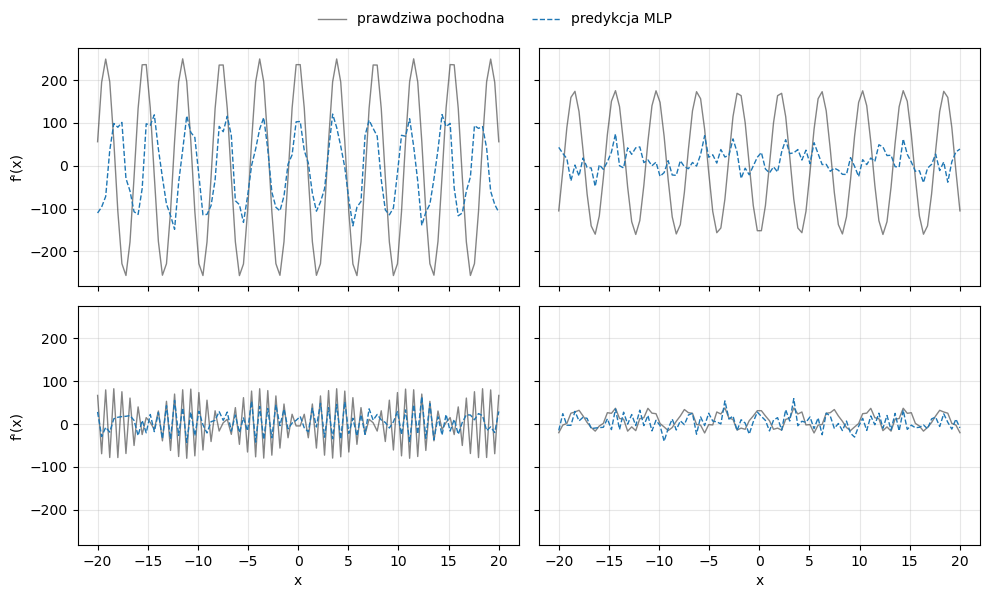

In [159]:
# import numpy as np
# import matplotlib.pyplot as plt
# import torch

model.eval()

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()

sample_indices = list(range(0, len(X_test), 5))[:4]
x_axis = np.linspace(-20, 20, num_of_steps)

for i, sample_idx in enumerate(sample_indices):

    x_sample = torch.tensor(X_test[sample_idx], dtype=torch.float32).unsqueeze(0)

    with torch.no_grad():
        pred_scaled = model(x_sample).cpu().numpy()

    pred = scaler_Y.inverse_transform(pred_scaled)[0]
    true = scaler_Y.inverse_transform(
        Y_test[sample_idx].reshape(1, -1)
    )[0]

    ax = axes[i]
    ax.plot(x_axis, true, color=true_color, linewidth=line_width, alpha=0.6)
    ax.plot(x_axis, pred, color=pred_color, linestyle="--", linewidth=line_width)
    ax.grid(alpha=0.3)

    # Y label tylko lewa kolumna
    if i % 2 == 0:
        ax.set_ylabel("f'(x)")

    # X label tylko dolny rząd
    if i >= 2:
        ax.set_xlabel("x")

# jedna globalna legenda
fig.legend(
    ["prawdziwa pochodna", "predykcja MLP"],
    loc="upper center",
    ncol=2,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

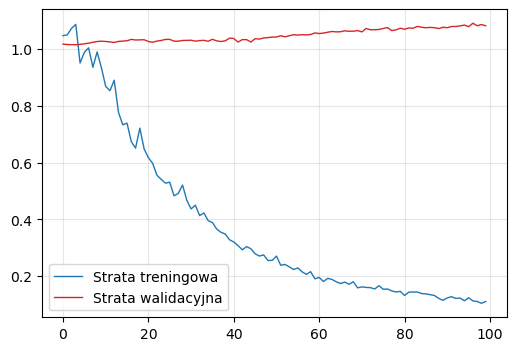

In [160]:
plt.figure(figsize=(6, 4))

plt.plot(train_losses, label='Strata treningowa', color=train_color, linewidth=line_width)
plt.plot(val_losses, label='Strata walidacyjna', color=val_color, linewidth=line_width)

# plt.yscale('log')
# plt.title('Historia uczenia (MSE)')
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [151]:
# # 1. asymetryczna funkcja 2D
# def f(x, y):
#     return np.sin( 2*(x+2)**2 + 7*(y+1)**2)# * np.cos( 5*y - 3 )

# # 2. siatka ciągła
# x = np.linspace(-1, 1, 200)
# y = np.linspace(-1, 1, 200)
# X, Y = np.meshgrid(x, y)
# Z = f(X, Y)

# # 3. siatka 10x10
# xg_1 = np.linspace(-1, 1, 10)
# yg_1 = np.linspace(-1, 1, 10)
# Xg_1, Yg_1 = np.meshgrid(xg_1, yg_1)

# # 4. siatka 30x30
# xg_2 = np.linspace(-1, 1, 30)
# yg_2 = np.linspace(-1, 1, 30)
# Xg_2, Yg_2 = np.meshgrid(xg_2, yg_2)

# # 5. wykresy
# fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True)

# titles = [
#     "Funkcja ciągła",
#     "Siatka o niskiej rozdzielczości",
#     "Siatka o wysokiej rozdzielczości",
# ]

# grids = [None, (Xg_1, Yg_1), (Xg_2, Yg_2)]

# for i, ax in enumerate(axes):
#     cf = ax.contourf(X, Y, Z, levels=60, cmap="cividis")

#     if grids[i] is not None:
#         Xg, Yg = grids[i]
#         # ax.scatter(Xg, Yg, marker='x', color="black", s=20)
#         ax.scatter(Xg, Yg, facecolors="none", edgecolor="black", s=10)

#     ax.set_title(titles[i])
#     # ax.set_xlabel("x")
#     ax.set_xticks([])
#     ax.set_xlim(-1, 1)
#     ax.set_ylim(-1, 1)

# # axes[0].set_ylabel("y")
# ax.set_yticks([])
# plt.tight_layout()
# plt.show()